In [ ]:
#Datos de generación de energía solar para la ZMG, recopilados en intervalos de 1 día durante un periodo de mas de 10,000 días.
#Existe un conjunto de datos: sobre la generación de energía solar correspondiente a las lecturas de los sensores instalados de la NASA POWER.
#Los sensores proporcionan la irradiancia; todas estas lecturas se registran en intervalos de 1 día, mes y año.


In [ ]:
#PREGUNTAS A RESPONDER PARA AURA JALISCO
#1. ¿Podemos predecir la generación de energía para los próximos días? Esto permite una mejor gestión de la red eléctrica a futuro.
#2. ¿Podemos identificar equipos averiados o que no están funcionando de manera óptima y en que epoca fallaron?

### Carga de DATASET y librerias

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import time
import warnings
warnings.filterwarnings('ignore')

In [ ]:

# Intentamos leer el archivo omitiendo posibles líneas de metadatos/comentarios comunes en NASA POWER
try:
    # La mayoría de archivos de la NASA usan '-' o '#' como comentarios, o tienen unas 10-15 líneas de cabecera
    df = pd.read_csv('/content/NASA_SOLAR.csv', comment='#', skiprows=10)
except Exception:
    # Si falla, intentamos leer de forma flexible con delimitador automático o skipping dinámico
    df = pd.read_csv('/content/NASA_SOLAR.csv', on_bad_lines='skip')

df.head(15)

,1996,1,1.1,5.3635
0,1996,1,2,4.9097
1,1996,1,3,3.4937
2,1996,1,4,5.0813
3,1996,1,5,5.5442
4,1996,1,6,5.3446
5,1996,1,7,5.3990
6,1996,1,8,4.2574
7,1996,1,9,4.7542
8,1996,1,10,5.0354
9,1996,1,11,4.9025


### Analisis de datos y exploración

In [ ]:
# Definimos los nombres deseados para las columnas
columnas = ['Año', 'Mes', 'Día', 'Irradiancia']

# Leemos el archivo asignando la lista de nombres a las 4 columnas
df = pd.read_csv('/content/NASA_SOLAR.csv', skiprows=10, header=None, names=columnas)

# Mostramos las primeras filas con los nuevos nombres de columna
df.head()

,Año,Mes,Día,Irradiancia
0,1996,1,1,5.3635
1,1996,1,2,4.9097
2,1996,1,3,3.4937
3,1996,1,4,5.0813
4,1996,1,5,5.5442


In [ ]:
# Comprobamos el cambio de nombre de las columnas
print(df.columns)

Index(['Año', 'Mes', 'Día', 'Irradiancia'], dtype='object')


In [ ]:
# Vemos la infromacion del df
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10652 entries, 0 to 10651
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Año          10652 non-null  int64  
 1   Mes          10652 non-null  int64  
 2   Día          10652 non-null  int64  
 3   Irradiancia  10652 non-null  float64
dtypes: float64(1), int64(3)
memory usage: 333.0 KB


In [ ]:
# Vemos sus estadisticos

df.describe()

,Año,Mes,Día,Irradiancia
count,10652.000000,10652.000000,10652.000000,10652.000000
mean,2010.083083,6.494649,15.728126,5.917035
std,8.418360,3.459935,8.799740,1.321157
min,1996.000000,1.000000,1.000000,0.798200
25%,2003.000000,3.000000,8.000000,5.106950
50%,2010.000000,7.000000,16.000000,5.872900
75%,2017.000000,10.000000,23.000000,6.925000
max,2025.000000,12.000000,31.000000,8.828400


In [ ]:
# Crear la columna DATE_TIME a partir de Año, Mes y Día, y establecerla como índice
## Esta mueva columna contiene la fecha completa
df['DATE_TIME'] = pd.to_datetime(df[['Año', 'Mes', 'Día']].rename(columns={'Año': 'year', 'Mes': 'month', 'Día': 'day'}))
df.set_index('DATE_TIME', inplace=True)
df.head()

,Año,Mes,Día,Irradiancia
DATE_TIME,,,,
1996-01-01,1996,1,1,5.3635
1996-01-02,1996,1,2,4.9097
1996-01-03,1996,1,3,3.4937
1996-01-04,1996,1,4,5.0813
1996-01-05,1996,1,5,5.5442


In [ ]:
print("Vista previa del dataset procesado:")
df.sample(15)

Vista previa del dataset procesado:


,Año,Mes,Día,Irradiancia
DATE_TIME,,,,
2005-06-06,2005,6,6,7.4887
2003-05-13,2003,5,13,7.4616
2013-12-23,2013,12,23,4.7165
2020-01-11,2020,1,11,5.3580
2008-09-15,2008,9,15,2.6340
2014-06-22,2014,6,22,5.7475
2023-09-30,2023,9,30,3.9334
2009-12-10,2009,12,10,5.2178
2017-07-12,2017,7,12,5.5522


In [ ]:
#Revisamos datos nulos
df.isna().sum()

,0
Año,0
Mes,0
Día,0
Irradiancia,0


### Grafica de tendencia anual y promedio medio

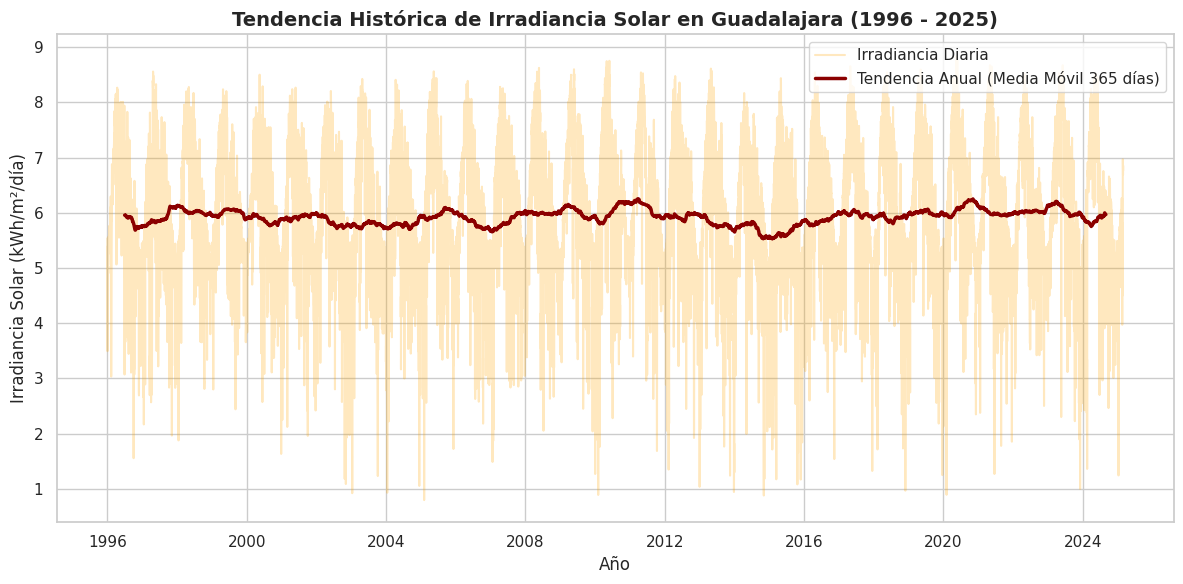

In [ ]:
# Configurar el estilo gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Graficamos los datos diarios con transparencia
plt.plot(df.index, df['Irradiancia'], alpha=0.25, color='orange', label='Irradiancia Diaria')

# Línea de Tendencia con Media Móvil de 365 días (1 año)
df['Tendencia_365d'] = df['Irradiancia'].rolling(window=365, center=True).mean()
plt.plot(df.index, df['Tendencia_365d'], color='darkred', linewidth=2.5, label='Tendencia Anual (Media Móvil 365 días)')

plt.title('Tendencia Histórica de Irradiancia Solar en Guadalajara (1996 - 2025)', fontsize=14, fontweight='bold')
plt.xlabel('Año', fontsize=12)
plt.ylabel('Irradiancia Solar (kWh/m²/día)', fontsize=12)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Tendencia por mes en mapa de calor

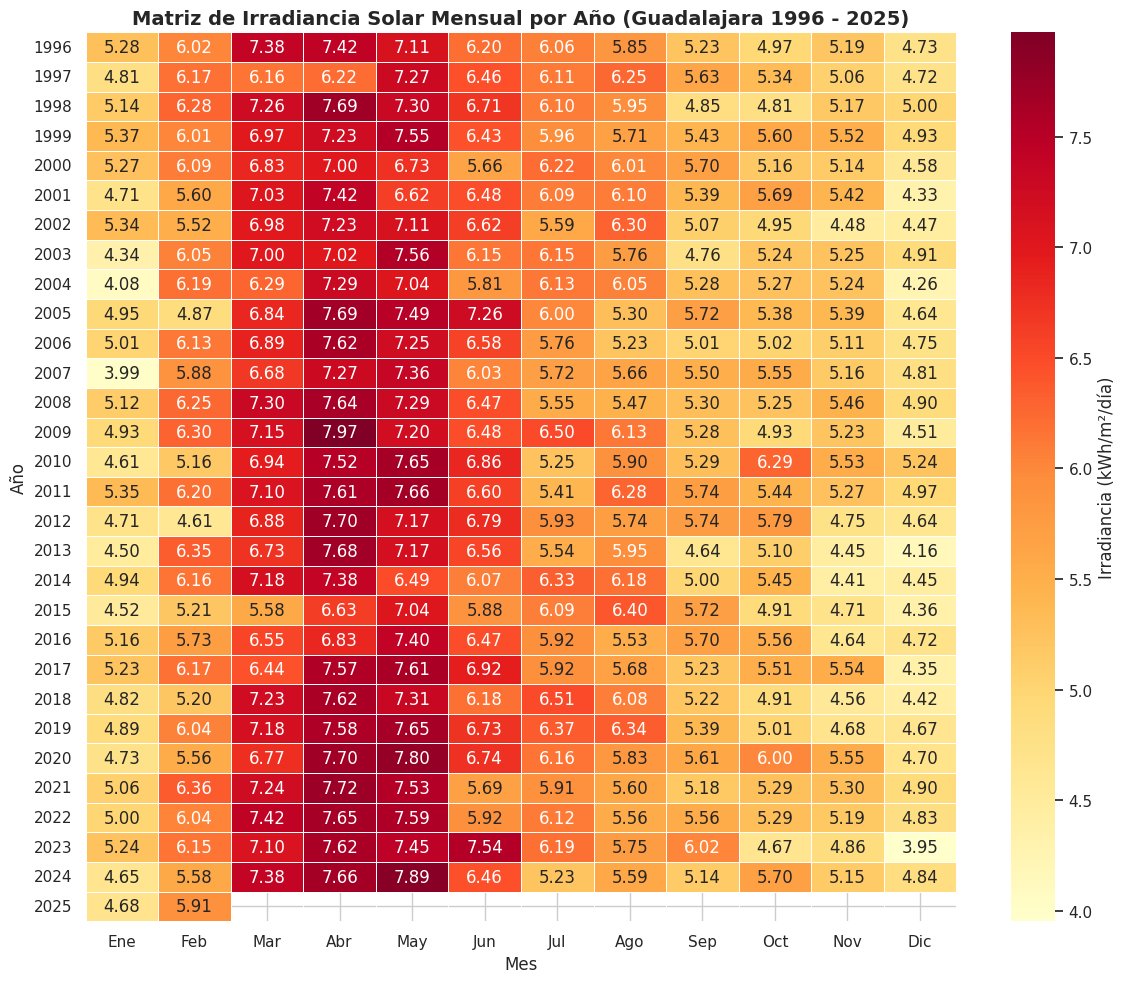

In [ ]:

# 1. Crear una tabla tipo correlacion de irrandancia : Filas = Año, Columnas = Mes, Valores = Promedio de Irradiancia
pivote_mensual = df.pivot_table(index='Año', columns='Mes', values='Irradiancia', aggfunc='mean')

# Renombramos columnas a nombres de meses
meses_nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
pivote_mensual.columns = meses_nombres

# Graficar la Matriz de Calor (Heatmap)
plt.figure(figsize=(12, 10))
sns.heatmap(pivote_mensual, cmap='YlOrRd', annot=True, fmt=".2f", linewidths=0.5, cbar_kws={'label': 'Irradiancia (kWh/m²/día)'})

plt.title('Matriz de Irradiancia Solar Mensual por Año (Guadalajara 1996 - 2025)', fontsize=14, fontweight='bold')
plt.xlabel('Mes', fontsize=12)
plt.ylabel('Año', fontsize=12)
plt.tight_layout()
plt.show()

# Grafica de la NASA

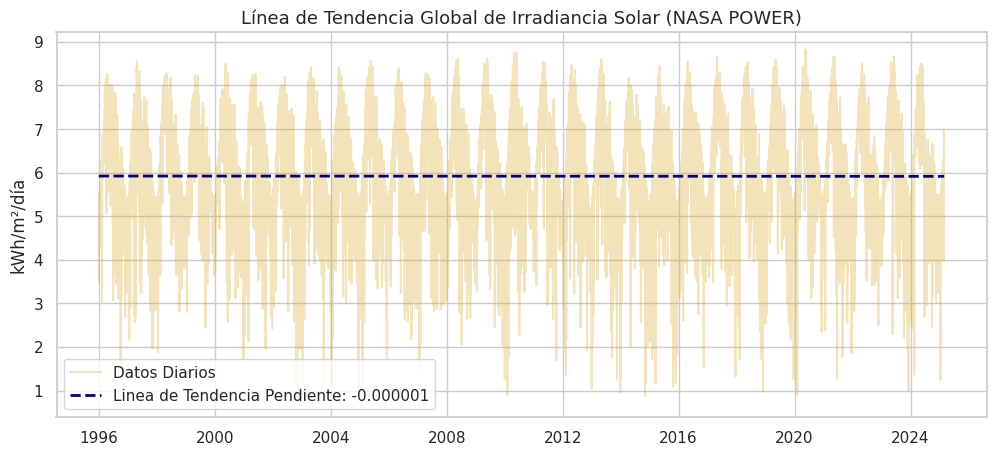

In [ ]:


plt.figure(figsize=(12, 5))

# Crear un índice numérico para calcular la regresión
x_numeric = np.arange(len(df))
y = df['Irradiancia'].values

# Ajuste lineal (grado 1)
coef = np.polyfit(x_numeric, y, 1)
linea_tendencia = np.polyval(coef, x_numeric)

# Graficar
plt.plot(df.index, df['Irradiancia'], alpha=0.3, color='goldenrod', label='Datos Diarios')
plt.plot(df.index, linea_tendencia, color='navy', linestyle='--', linewidth=2, label=f'Linea de Tendencia Pendiente: {coef[0]:.6f}')

plt.title('Línea de Tendencia Global de Irradiancia Solar (NASA POWER)', fontsize=13)
plt.ylabel('kWh/m²/día')
plt.legend()
plt.show()

# Histogramas de mediciones de año

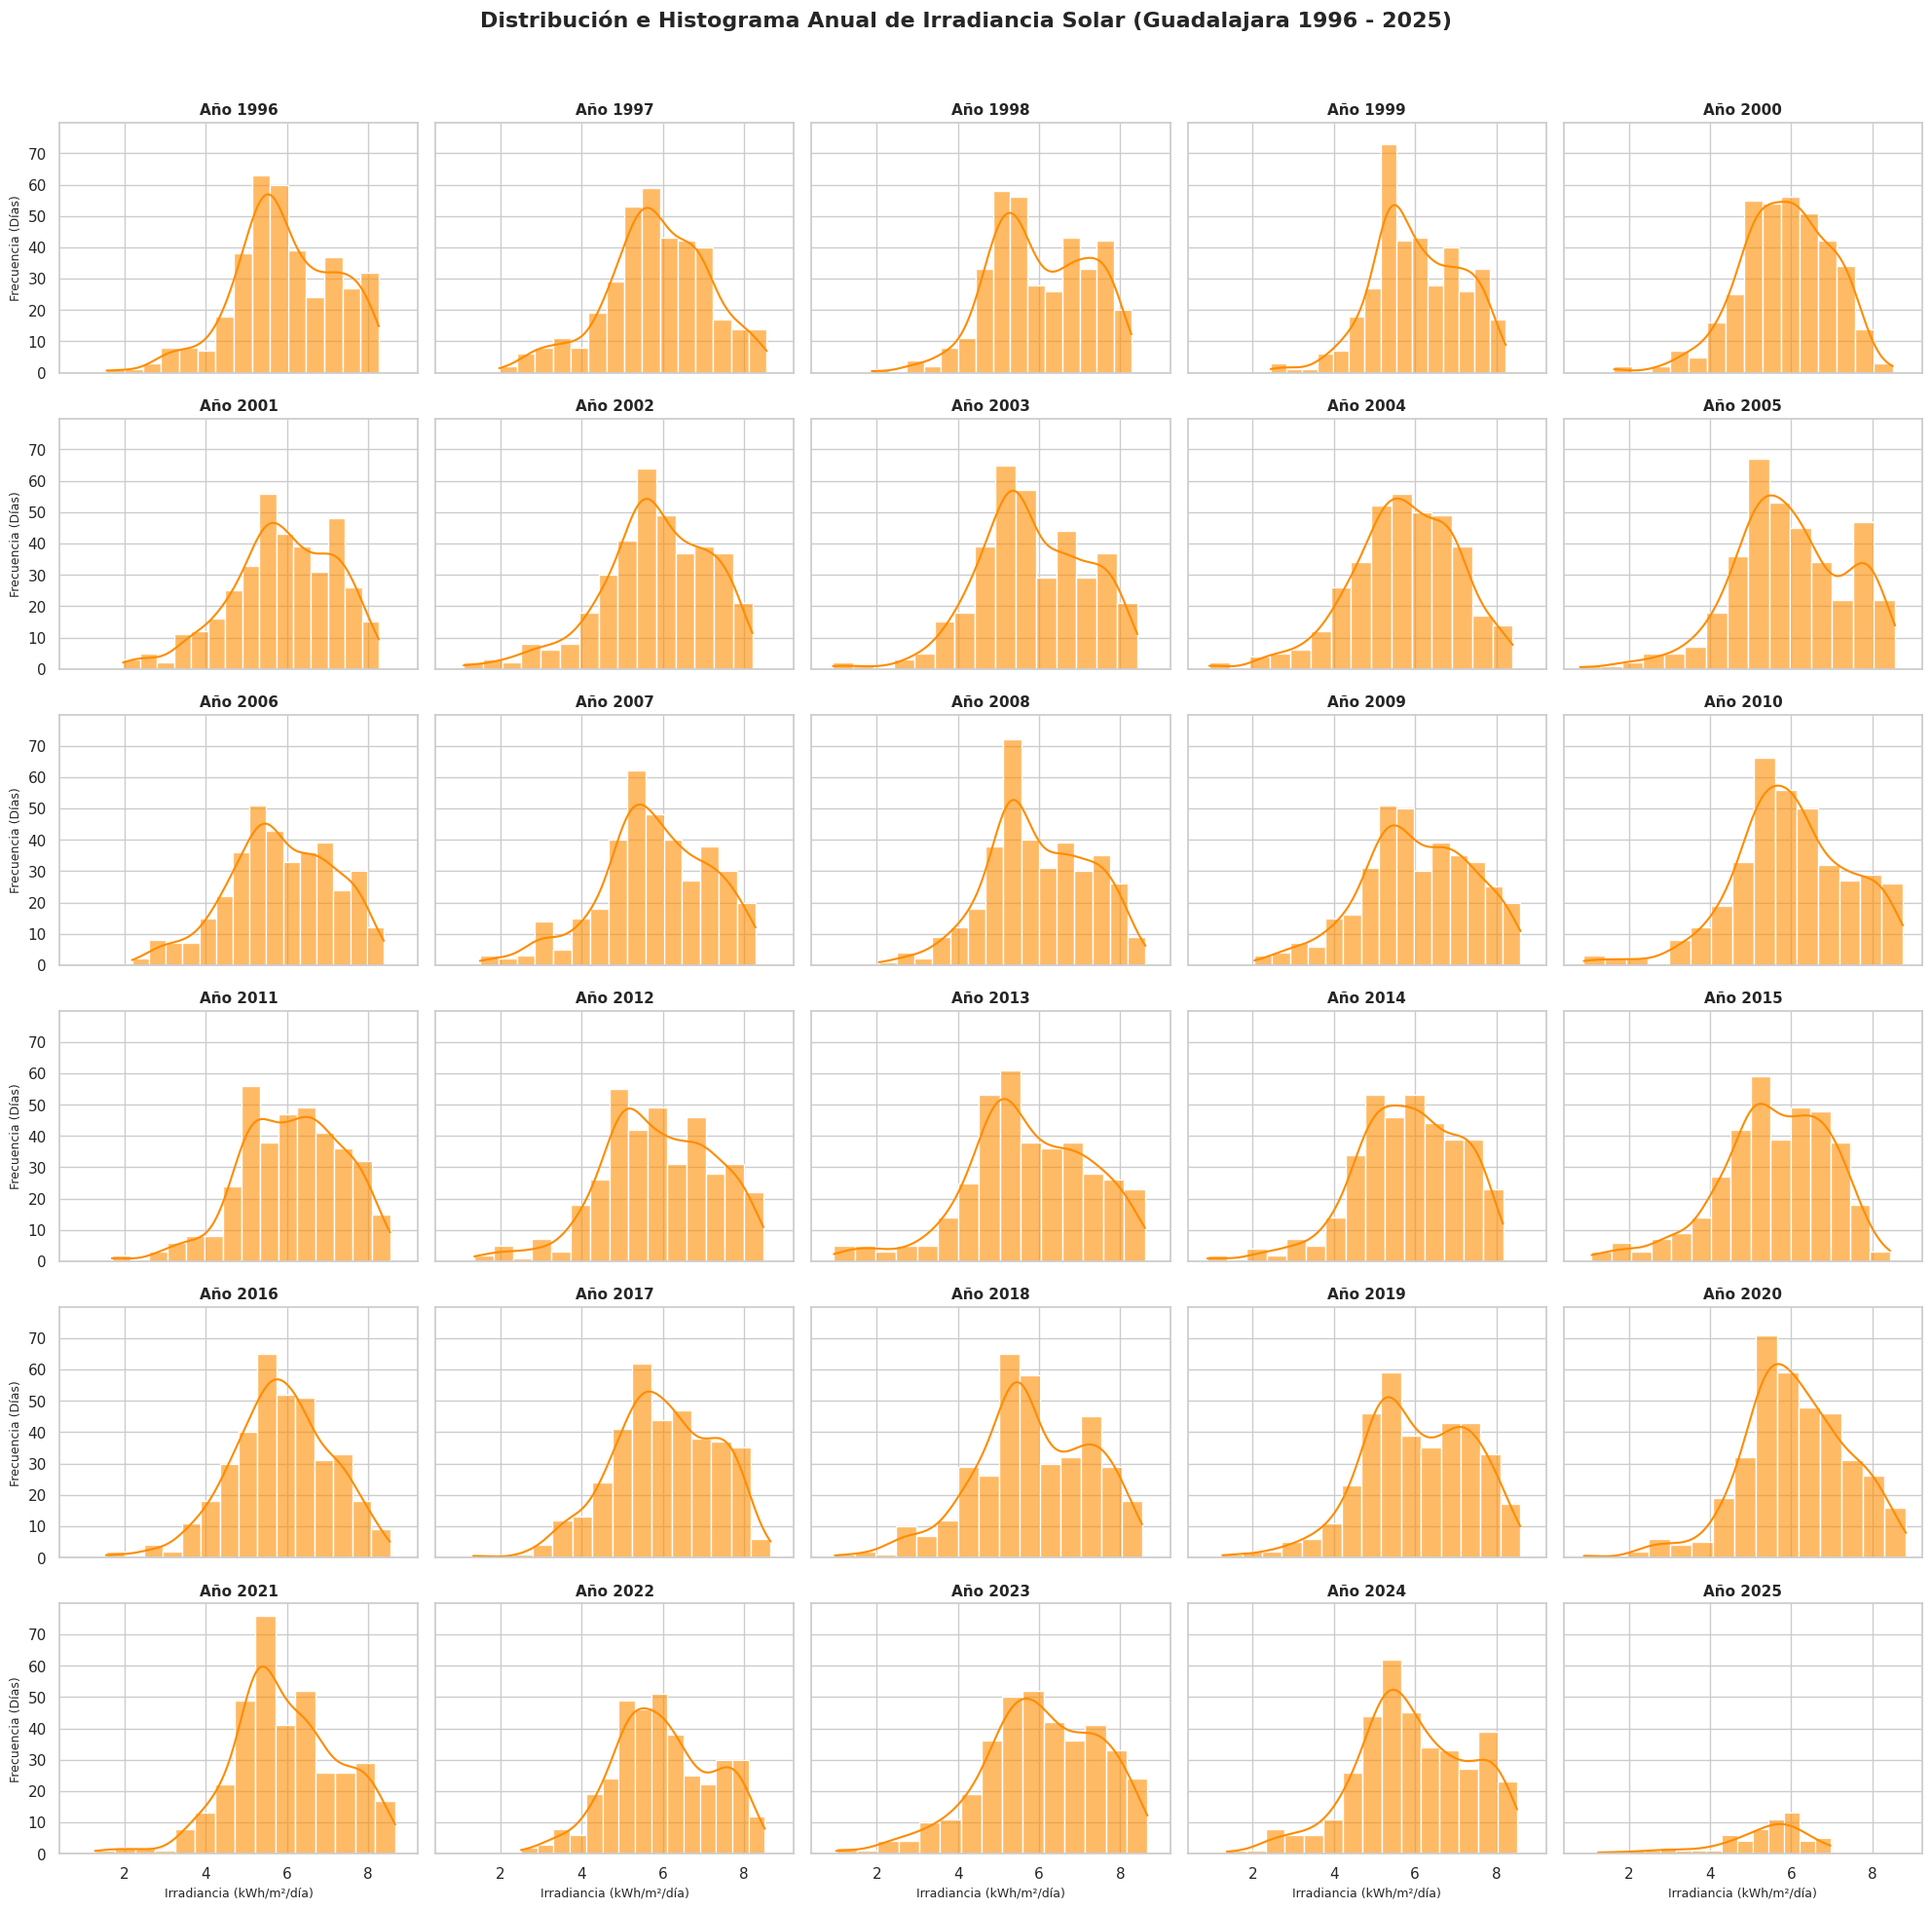

In [ ]:
# Configurar el estilo visual del estilo
sns.set_theme(style="whitegrid")

# Obtener la lista de años únicos ordenados con sorted
anos_unicos = sorted(df['Año'].unique())
num_anos = len(anos_unicos)

# Calcular filas y columnas para la cuadrícula de gráficos (5 columnas)
cols = 5
rows = int(np.ceil(num_anos / cols))

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 3.2), sharex=True, sharey=True)
axes = axes.flatten()

# Graficar el histograma para cada año
for i, ano in enumerate(anos_unicos):
    datos_ano = df[df['Año'] == ano]['Irradiancia']

    # Histograma con curva de densidad (KDE)
    sns.histplot(datos_ano, kde=True, ax=axes[i], color='darkorange', bins=15, alpha=0.6)

    # Formato individual por subtítulo
    axes[i].set_title(f'Año {ano}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Irradiancia (kWh/m²/día)', fontsize=9)
    axes[i].set_ylabel('Frecuencia (Días)', fontsize=9)

# Ocultar los cuadros/subejes vacíos sobrantes al final de la cuadrícula
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Distribución e Histograma Anual de Irradiancia Solar (Guadalajara 1996 - 2025)',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Calculo IQR por promedio de 30 años

--- Análisis Estadístico de Outliers (IQR) ---
Primer Cuartil (Q1): 5.11 kWh/m²/día
Tercer Cuartil (Q3): 6.92 kWh/m²/día
Rango Intercuartílico (IQR): 1.82 kWh/m²/día
Límite Inferior Estadístico: 2.38 kWh/m²/día
Límite Superior Estadístico: 9.65 kWh/m²/día
Días por debajo del límite inferior (Días muy nublados): 110
Días por encima del límite superior: 0


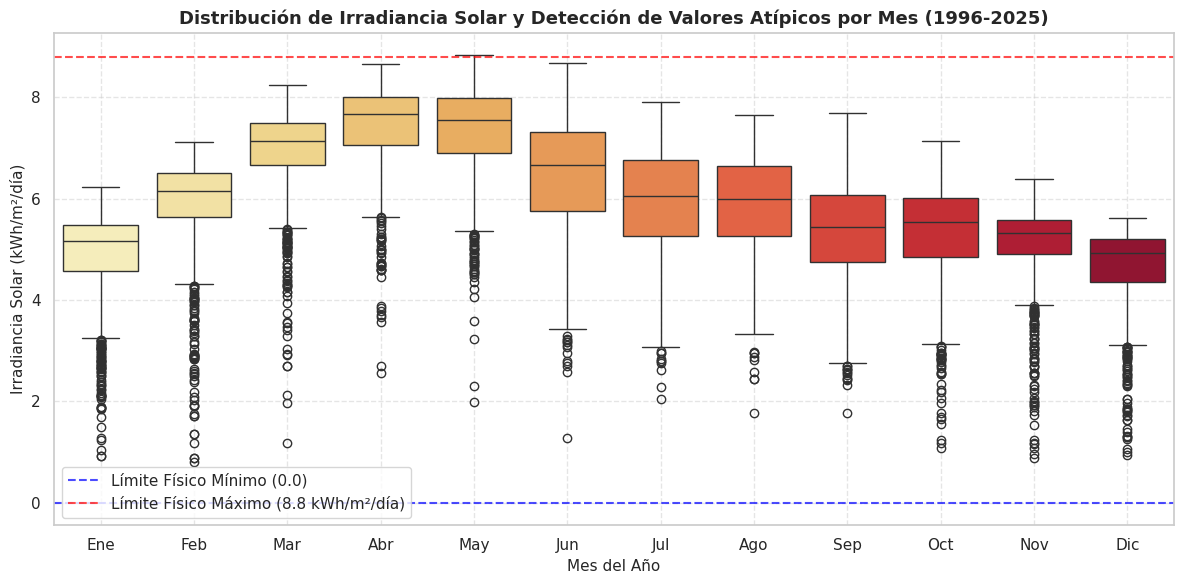

In [ ]:
# 1. Cálculo del IQR global para la Irradiancia Solar
Q1 = df['Irradiancia'].quantile(0.25)
Q3 = df['Irradiancia'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"--- Análisis Estadístico de Outliers (IQR) ---")
print(f"Primer Cuartil (Q1): {Q1:.2f} kWh/m²/día")
print(f"Tercer Cuartil (Q3): {Q3:.2f} kWh/m²/día")
print(f"Rango Intercuartílico (IQR): {IQR:.2f} kWh/m²/día")
print(f"Límite Inferior Estadístico: {limite_inferior:.2f} kWh/m²/día")
print(f"Límite Superior Estadístico: {limite_superior:.2f} kWh/m²/día")

# Contar cuántos datos caen fuera del rango IQR
outliers_bajos = df[df['Irradiancia'] < limite_inferior]
outliers_altos = df[df['Irradiancia'] > limite_superior]
print(f"Días por debajo del límite inferior (Días muy nublados): {len(outliers_bajos)}")
print(f"Días por encima del límite superior: {len(outliers_altos)}")

# 2. Visualización con Diagrama de Caja (Boxplot) por Mes
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Mes', y='Irradiancia', palette='YlOrRd')

# Dibujar líneas horizontales de los límites físicos teóricos de Guadalajara (0 a 8.8)
plt.axhline(y=0.0, color='blue', linestyle='--', alpha=0.7, label='Límite Físico Mínimo (0.0)')
plt.axhline(y=8.8, color='red', linestyle='--', alpha=0.7, label='Límite Físico Máximo (8.8 kWh/m²/día)')

meses_nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
plt.xticks(ticks=range(0, 12), labels=meses_nombres)

plt.title('Distribución de Irradiancia Solar y Detección de Valores Atípicos por Mes (1996-2025)', fontsize=13, fontweight='bold')
plt.xlabel('Mes del Año', fontsize=11)
plt.ylabel('Irradiancia Solar (kWh/m²/día)', fontsize=11)
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Datos estadisticos de los 30 años.

In [ ]:
# 1. Crear un diccionario explícito que vincula la Clave (Número) con el Valor (Texto)
diccionario_meses = {
    1: 'Enero',      2: 'Febrero',   3: 'Marzo',      4: 'Abril',
    5: 'Mayo',       6: 'Junio',     7: 'Julio',      8: 'Agosto',
    9: 'Septiembre', 10: 'Octubre',  11: 'Noviembre', 12: 'Diciembre'
}

# 2. Crear una NUEVA columna llamada 'Nombre_Mes' en tu DataFrame original
# 'map' toma cada número de la columna 'Mes' (1, 2, 3...) y busca su equivalente en texto en el diccionario
df['Nombre_Mes'] = df['Mes'].map(diccionario_meses)

# ¿Cómo se ve ahora tu df?
# Tu df ahora tiene las dos columnas: 'Mes' (ej. 5) y 'Nombre_Mes' (ej. 'Mayo')
# Función personalizada para calcular el IQR y el Rango Total
# Definir funciones auxiliares explícitas
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

def rango_total(x):
    return x.max() - x.min()

# 3. Agrupar por 'Nombre_Mes' (Pandas usará los nombres directamente)
estadisticos_mensuales = df.groupby('Nombre_Mes', sort=False)['Irradiancia'].agg(
    Media='mean',
    Mediana='median',
    Desv_Estd='std',
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75),
    IQR=iqr,
    Minimo='min',
    Maximo='max',
    Rango=rango_total,
    Asimetria='skew',
    Curtosis=lambda x: x.kurtosis()
).reset_index()

# Redondear a 3 decimales para reporte académico
estadisticos_mensuales = estadisticos_mensuales.round(3)

# Mostrar la tabla final
display(estadisticos_mensuales)

,Nombre_Mes,Media,Mediana,Desv_Estd,Q1,Q3,IQR,Minimo,Maximo,Rango,Asimetria,Curtosis
0,Enero,4.881,5.169,0.924,4.582,5.489,0.907,0.923,6.221,5.298,-1.553,2.341
1,Febrero,5.858,6.153,1.045,5.633,6.506,0.873,0.798,7.126,6.328,-2.105,5.120
2,Marzo,6.914,7.134,0.915,6.657,7.483,0.826,1.175,8.245,7.070,-2.111,6.249
3,Abril,7.420,7.664,0.862,7.054,7.998,0.945,2.568,8.651,6.083,-1.810,4.597
4,Mayo,7.320,7.545,0.949,6.908,7.982,1.074,1.996,8.828,6.833,-1.401,2.765
5,Junio,6.440,6.655,1.203,5.762,7.320,1.558,1.271,8.670,7.400,-0.790,0.375
6,Julio,5.959,6.062,1.058,5.259,6.757,1.498,2.054,7.914,5.860,-0.599,0.144
7,Agosto,5.868,5.985,0.997,5.254,6.640,1.386,1.780,7.658,5.878,-0.644,0.217
8,Septiembre,5.356,5.449,0.975,4.746,6.076,1.330,1.767,7.684,5.918,-0.507,0.270
9,Octubre,5.313,5.530,1.002,4.853,6.018,1.165,1.082,7.128,6.045,-1.174,1.593


# Correlación entre 1,2,3 y 8 dias

### ¿Podemos predecir la generación de energía para los próximos días? Esto permite una mejor gestión de la red eléctrica.

Esta matriz mide la memoria de los datos. Te dice qué tanto influye el sol de días pasados en el sol que habrá hoy.

Demuestra cuantitativamente que se deben alimentar al algoritmo con los datos de al menos 1 a 3 días previos ($t-1, t-2, t-3$) como variables de entrada (inputs), siendo $t-1$ el retardo con mayor peso explicativo ($r = 0.77$).

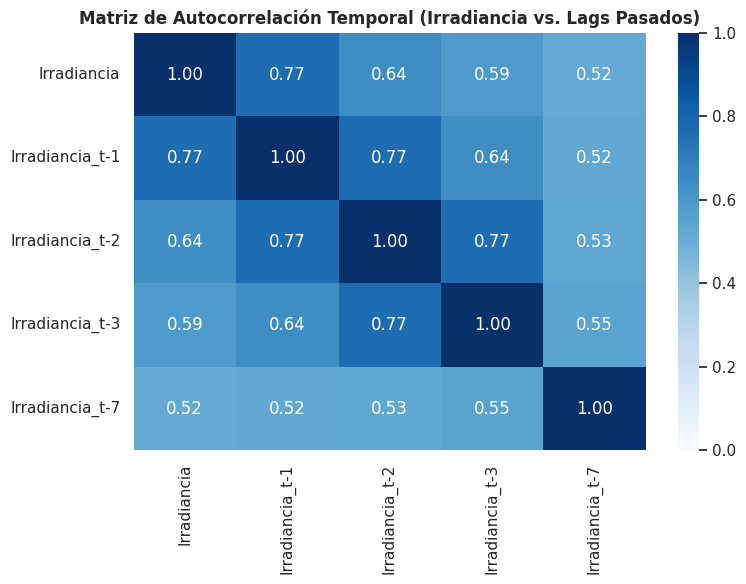

In [ ]:
# 1. Crear variables de retardo (Lags) para la irradiancia diaria
df_corr = df[['Irradiancia']].copy()

# Generar retardos: irradiancia de hace 1 día (t-1), 2 días (t-2), 3 días (t-3) y 7 días (t-7)
df_corr['Irradiancia_t-1'] = df_corr['Irradiancia'].shift(1)
df_corr['Irradiancia_t-2'] = df_corr['Irradiancia'].shift(2)
df_corr['Irradiancia_t-3'] = df_corr['Irradiancia'].shift(3)
df_corr['Irradiancia_t-7'] = df_corr['Irradiancia'].shift(7)

# 2. Calcular la matriz de correlación eliminando los valores nulos generados por el shift
matriz_correlacion = df_corr.dropna().corr()

# 3. Graficar el Heatmap adaptado
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_correlacion, cmap='Blues', annot=True, fmt=".2f", vmin=0, vmax=1)

plt.title('Matriz de Autocorrelación Temporal (Irradiancia vs. Lags Pasados)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Moficamos el df para los modelos, juntamos todas las variables x en la columna DATA_TIME y dejamos IRRADANCIA.

In [ ]:
# 1. Asegurar que la columna de fecha sea el índice temporal del DataFrame
df['DATE_TIME'] = pd.to_datetime(df[['Año', 'Mes', 'Día']].rename(columns={'Año': 'year', 'Mes': 'month', 'Día': 'day'}))

# Como 'DATE_TIME' ya podría estar establecido o necesitamos reconstruir el índice de forma limpia:
if 'DATE_TIME' not in df.index.names:
    df = df.set_index('DATE_TIME')

# 2. Seleccionar únicamente la columna de Irradiancia diaria procesada
df_diario = df[['Irradiancia']].copy()

# Visualizar los primeros registros diarios sin ruido nocturno
df_diario.head()

,Irradiancia
DATE_TIME,
1996-01-01,5.3635
1996-01-02,4.9097
1996-01-03,3.4937
1996-01-04,5.0813
1996-01-05,5.5442


In [ ]:
# Hacemos copia del DF diario para comenzar los modelos
df_diario = df[['Irradiancia']].copy()

# erificar la continuidad del índice temporal (1 registro diario desde 1996 a 2025)
df_diario.info()

# Visualizamos el resultado diario listo para construir Lags o escalamiento
df_diario.head()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 10652 entries, 1996-01-01 to 2025-02-28
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Irradiancia  10652 non-null  float64
dtypes: float64(1)
memory usage: 166.4 KB


,Irradiancia
DATE_TIME,
1996-01-01,5.3635
1996-01-02,4.9097
1996-01-03,3.4937
1996-01-04,5.0813
1996-01-05,5.5442


In [ ]:
# Reciusamos que no contenga datos nulos
df_diario.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 10652 entries, 1996-01-01 to 2025-02-28
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Irradiancia  10652 non-null  float64
dtypes: float64(1)
memory usage: 166.4 KB


In [ ]:
df_diario.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 10652 entries, 1996-01-01 to 2025-02-28
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Irradiancia  10652 non-null  float64
dtypes: float64(1)
memory usage: 166.4 KB


## Comenzamis con los modelos de ML.

En el EDA demostramos que tus datos solares presentan una distribución no Gaussiana (asimétrica a la izquierda y bimodal). Además, los árboles de decisión no requieren escalamiento de características porque realizan divisiones jerárquicas basadas en umbrales.


## Modelo de regresion lineal

Variable Target ($y$): Es la Irradiancia del día de hoy ($t$), que es el valor futuro que el modelo quiere adivinar. Por eso hacemos y = df_ml['Irradiancia'].Matriz de Predictores ($X$): Son las características pasadas y temporales (es decir: Irradiancia_t-1, Irradiancia_t-2, Irradiancia_t-3, Sin_Dia_Anio, Cos_Dia_Anio). Por eso al escribir X = df_ml.drop(columns=['Irradiancia']), le quitamos a $X$ la irradiancia actual para que no "haga trampa" consultando el resultado de hoy.

In [ ]:
#Importamos librerias de la regresión
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [ ]:
# Revisamos columnas
df_diario.columns

Index(['Irradiancia'], dtype='object')

In [ ]:
# Partimos de tu DataFrame diario limpio
df_ml = df_diario.copy()

# 1. Crear las variables de retardo (Lags) para los días anteriores
df_ml['Irradiancia_t-1'] = df_ml['Irradiancia'].shift(1)
df_ml['Irradiancia_t-2'] = df_ml['Irradiancia'].shift(2)
df_ml['Irradiancia_t-3'] = df_ml['Irradiancia'].shift(3)

# 2. Extraer día del año y codificación cíclica (Seno / Coseno)
df_ml['Dia_Anio'] = df_ml.index.dayofyear
df_ml['Sin_Dia_Anio'] = np.sin(2 * np.pi * df_ml['Dia_Anio'] / 365.25)
df_ml['Cos_Dia_Anio'] = np.cos(2 * np.pi * df_ml['Dia_Anio'] / 365.25)

# 3. Eliminar la columna auxiliar 'Dia_Anio' y las filas con NaN generadas por los shifts
df_ml = df_ml.drop(columns=['Dia_Anio']).dropna()

# Comprobar que df_ml existe y tiene las columnas adecuadas
df_ml.head()

,Irradiancia,Irradiancia_t-1,Irradiancia_t-2,Irradiancia_t-3,Sin_Dia_Anio,Cos_Dia_Anio
DATE_TIME,,,,,,
1996-01-04,5.0813,3.4937,4.9097,5.3635,0.068755,0.997634
1996-01-05,5.5442,5.0813,3.4937,4.9097,0.085906,0.996303
1996-01-06,5.3446,5.5442,5.0813,3.4937,0.103031,0.994678
1996-01-07,5.3990,5.3446,5.5442,5.0813,0.120126,0.992759
1996-01-08,4.2574,5.3990,5.3446,5.5442,0.137185,0.990545


In [ ]:
# 1. Definir matriz de entrada (X) y variable a predecir (y)
X = df_ml.drop(columns=['Irradiancia'])
y = df_ml['Irradiancia']

# 2. División temporal respetando la secuencia cronológica (shuffle=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print('Shape of X_train:', X_train.shape)
print('Shape of y_train:', y_train.shape)
print('Shape of X_test:', X_test.shape)
print('Shape of y_test:', y_test.shape)

# 3. Entrenar la Regresión Lineal
modelo_lr = LinearRegression()
modelo_lr.fit(X_train, y_train)

# 4. Predicción y Evaluación
y_pred = modelo_lr.predict(X_test)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("\n--- Resultados del Modelo de Regresión Lineal ---")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Raíz del MSE (RMSE): {rmse:.4f} kWh/m²/día")

Shape of X_train: (8519, 5)
Shape of y_train: (8519,)
Shape of X_test: (2130, 5)
Shape of y_test: (2130,)

--- Resultados del Modelo de Regresión Lineal ---
Coeficiente de Determinación (R²): 0.6637
Error Cuadrático Medio (MSE): 0.6057
Raíz del MSE (RMSE): 0.7783 kWh/m²/día


In [ ]:
# Creando el modelo de regresión lineal sin sobreescribir df_ml
modelo_lr_base = LinearRegression()
modelo_lr_base

LinearRegression()

In [ ]:
# Entrenando el modelo base de regresión lineal
modelo_lr_base.fit(X_train, y_train)

LinearRegression()

In [ ]:
# Predecir a partir de X_test usando el modelo base y verificar las dimensiones
y_pred_base = modelo_lr_base.predict(X_test)
y_pred_base.shape

(2130,)

In [ ]:
# Comprobar el rendimiento en X_test y el error del modelo base
r2score = r2_score(y_test, y_pred_base)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_base))
error = (rmse / y_test.mean()) * 100

print('R² Score :', round(r2score * 100, 2), '%', sep='')
print('Root Mean Squared Error is :', round(rmse, 2))
print('Relative Error Magnitude :', round(error, 2), '%', sep='')

R² Score :66.37%
Root Mean Squared Error is : 0.78
Relative Error Magnitude :13.03%


Graficas de Reg. Lineal

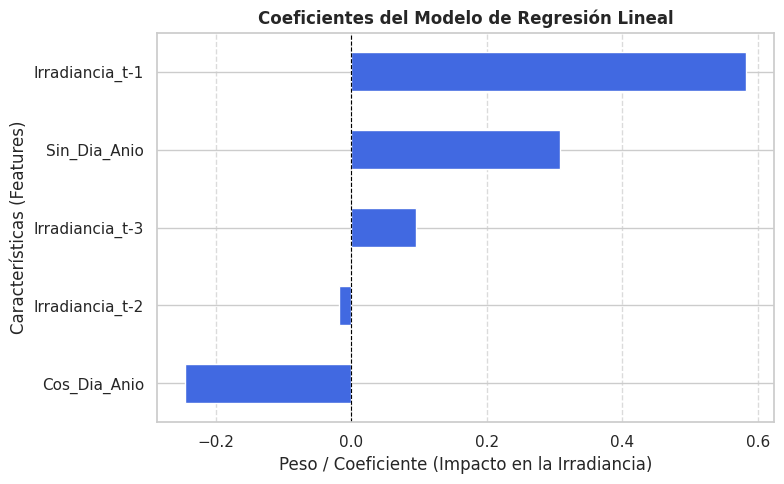

In [ ]:
coeficientes = pd.Series(modelo_lr.coef_, index=X_train.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
coeficientes.plot(kind='barh', color='royalblue')

plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.title('Coeficientes del Modelo de Regresión Lineal', fontsize=12, fontweight='bold')
plt.xlabel('Peso / Coeficiente (Impacto en la Irradiancia)')
plt.ylabel('Características (Features)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Serie de Tiempo (Irradiancia Real vs. Predicha)

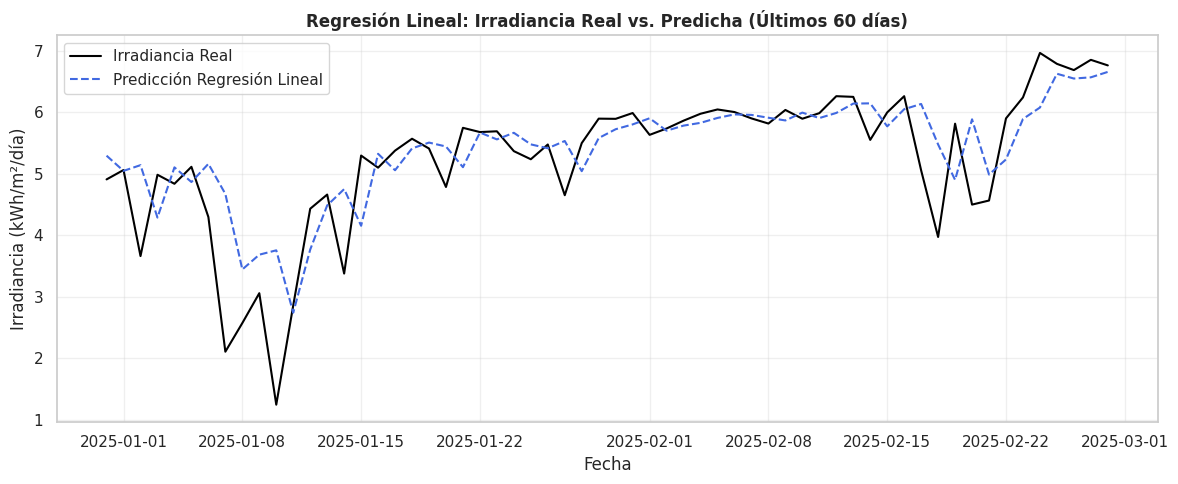

In [ ]:
plt.figure(figsize=(12, 5))

# Graficar los últimos 60 días del conjunto de test
dias = 60
plt.plot(y_test.index[-dias:], y_test.values[-dias:], label='Irradiancia Real', color='black', linewidth=1.5)
plt.plot(y_test.index[-dias:], y_pred_base[-dias:], label='Predicción Regresión Lineal', color='royalblue', linestyle='--', linewidth=1.5)

plt.title('Regresión Lineal: Irradiancia Real vs. Predicha (Últimos 60 días)', fontsize=12, fontweight='bold')
plt.ylabel('Irradiancia (kWh/m²/día)')
plt.xlabel('Fecha')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Dispersión (Scatter Plot de Validez de Ajuste)

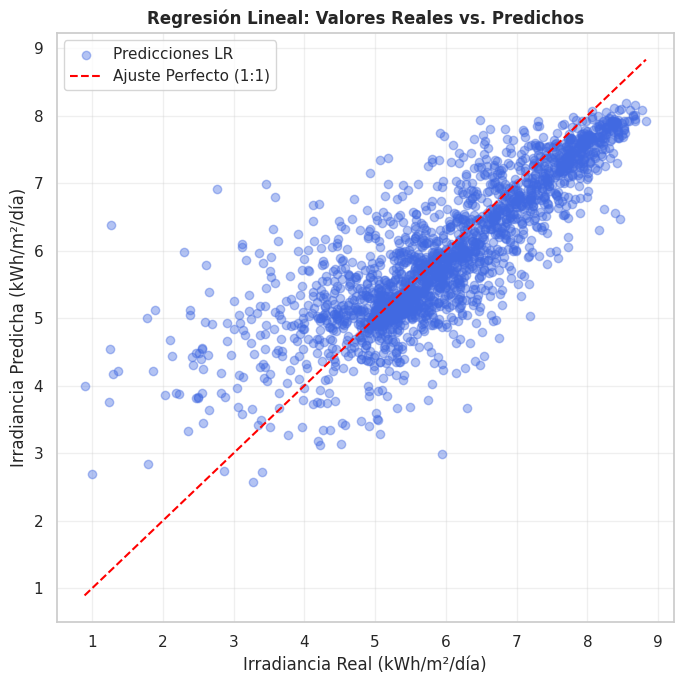

In [ ]:
plt.figure(figsize=(7, 7))

plt.scatter(y_test, y_pred_base, alpha=0.4, color='royalblue', label='Predicciones LR')

# Línea de referencia ideal (Predicción == Realidad)
lims = [min(y_test.min(), y_pred_base.min()), max(y_test.max(), y_pred_base.max())]
plt.plot(lims, lims, color='red', linestyle='--', label='Ajuste Perfecto (1:1)')

plt.title('Regresión Lineal: Valores Reales vs. Predichos', fontsize=12, fontweight='bold')
plt.xlabel('Irradiancia Real (kWh/m²/día)')
plt.ylabel('Irradiancia Predicha (kWh/m²/día)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Distribución de Residuos (Errores)

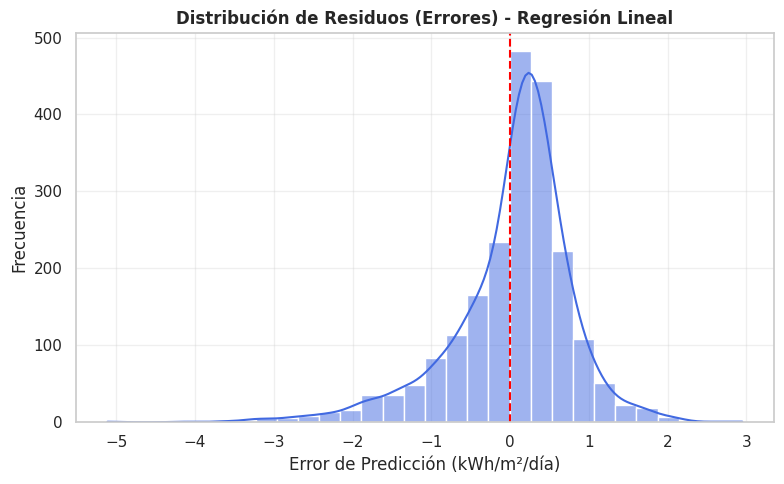

In [ ]:
residuos_lr = y_test - y_pred_base

plt.figure(figsize=(8, 5))
sns.histplot(residuos_lr, kde=True, color='royalblue', bins=30)
plt.axvline(x=0, color='red', linestyle='--', linewidth=1.5)

plt.title('Distribución de Residuos (Errores) - Regresión Lineal', fontsize=12, fontweight='bold')
plt.xlabel('Error de Predicción (kWh/m²/día)')
plt.ylabel('Frecuencia')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#Aqui comenzamos a hacer el Xboost y se termina la regresión lineal

#Generación de características y preparación de $X$ e $y$

In [ ]:
# Generamos los retardos explícitos usando .shift()
#    - 'Irradiancia_t-1': Irradiancia registrada AYER (1 día atrás)
#    - 'Irradiancia_t-2': Irradiancia registrada ANTEAYER (2 días atrás)
#    - 'Irradiancia_t-3': Irradiancia registrada HACE 3 DÍAS (3 días atrás)
df_ml['Irradiancia_t-1'] = df_ml['Irradiancia'].shift(1)
df_ml['Irradiancia_t-2'] = df_ml['Irradiancia'].shift(2)
df_ml['Irradiancia_t-3'] = df_ml['Irradiancia'].shift(3)

In [ ]:
# Eliminamos las primeras filas que contienen valores nulos (NaN) debido al desplazamiento
df_ml = df_ml.dropna()

In [ ]:
# Definimos la variable objetivo (y) como la Irradiancia del día actual
y = df_ml['Irradiancia'] # Toma SOLO la columna del día de hoy (t)

# Definimos la matriz de características (X) eliminando la columna 'Irradiancia'
X = df_ml.drop(columns=['Irradiancia']) # ELIMINA la columna del día de hoy

## Lo que le entregamos a X son únicamente las columnas con los retardos de días pasados (Irradiancia_t-1, Irradiancia_t-2, Irradiancia_t-3).

# verificamos qué columnas forman la matriz X y sus dimensiones
print("Variables predictoras (X):", list(X.columns))
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Variables predictoras (X): ['Irradiancia_t-1', 'Irradiancia_t-2', 'Irradiancia_t-3', 'Sin_Dia_Anio', 'Cos_Dia_Anio']
Dimensiones de X: (10643, 5)
Dimensiones de y: (10643,)


In [ ]:
# 1. Instanciar la validación cruzada temporal con 5 particiones
# Dividimos en folders basicamente de 5 años cada uno para nuestros datos
tscv = TimeSeriesSplit(n_splits=5)

print("--- ESTRUCTURA DE LAS PARTICIONES TEMPORALES (TimeSeriesSplit) ---")
print(f"Total de registros a evaluar: {len(X)}\n")

# 2. Inspeccionar los rangos de fechas de cada pliegue
for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
    f_train_start = X.index[train_idx[0]].strftime('%Y-%m-%d')
    f_train_end = X.index[train_idx[-1]].strftime('%Y-%m-%d')
    f_test_start = X.index[test_idx[0]].strftime('%Y-%m-%d')
    f_test_end = X.index[test_idx[-1]].strftime('%Y-%m-%d')

    print(f"Fold {fold + 1}:")
    print(f"  Entrenamiento ({len(train_idx)} días): {f_train_start}  -->  {f_train_end}")
    print(f"  Validación    ({len(test_idx)} días): {f_test_start}  -->  {f_test_end}\n")

--- ESTRUCTURA DE LAS PARTICIONES TEMPORALES (TimeSeriesSplit) ---
Total de registros a evaluar: 10643

Fold 1:
  Entrenamiento (1778 días): 1996-01-10  -->  2000-11-21
  Validación    (1773 días): 2000-11-22  -->  2005-09-29

Fold 2:
  Entrenamiento (3551 días): 1996-01-10  -->  2005-09-29
  Validación    (1773 días): 2005-09-30  -->  2010-08-07

Fold 3:
  Entrenamiento (5324 días): 1996-01-10  -->  2010-08-07
  Validación    (1773 días): 2010-08-08  -->  2015-06-15

Fold 4:
  Entrenamiento (7097 días): 1996-01-10  -->  2015-06-15
  Validación    (1773 días): 2015-06-16  -->  2020-04-22

Fold 5:
  Entrenamiento (8870 días): 1996-01-10  -->  2020-04-22
  Validación    (1773 días): 2020-04-23  -->  2025-02-28



In [ ]:

# ENTRENAMIENTO Y EVALUACIÓN CON GRADIENT BOOSTING REGRESSOR

# Instanciamos el modelo de Gradient Boosting Regressor
modelo_gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,
    random_state=42
)

# 2. Listas para almacenar las métricas de cada uno de los 5 folds
rmse_list = []
mae_list = []
r2_list = []

print("--- EVALUACIÓN POR CADA FOLD DE TIMESERIES SPLIT ---")

# 3. Iterar sobre las 5 particiones temporales
for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
    # Separación temporal para el fold actual
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Entrenar el modelo
    modelo_gb.fit(X_train, y_train)

    # Predecir sobre el conjunto de validación
    y_pred = modelo_gb.predict(X_test)

    # Calcular métricas
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # Guardar métricas
    rmse_list.append(rmse)
    mae_list.append(mae)
    r2_list.append(r2)

    print(f"Fold {fold + 1}: RMSE = {rmse:.4f} | MAE = {mae:.4f} | R² = {r2:.4f}")

# 4. Métricas globales promediadas
print("\n--- RESULTADOS GLOBALES DEL MODELO (PROMEDIO 5 FOLDS) ---")
print(f"RMSE Promedio: {np.mean(rmse_list):.4f} kWh/m²/día")
print(f"MAE Promedio:  {np.mean(mae_list):.4f} kWh/m²/día")
print(f"R² Promedio:   {np.mean(r2_list):.4f}")

--- EVALUACIÓN POR CADA FOLD DE TIMESERIES SPLIT ---
Fold 1: RMSE = 0.8543 | MAE = 0.6269 | R² = 0.5967
Fold 2: RMSE = 0.8222 | MAE = 0.5972 | R² = 0.6395
Fold 3: RMSE = 0.8322 | MAE = 0.5923 | R² = 0.6190
Fold 4: RMSE = 0.7871 | MAE = 0.5769 | R² = 0.6480
Fold 5: RMSE = 0.7527 | MAE = 0.5408 | R² = 0.6814

--- RESULTADOS GLOBALES DEL MODELO (PROMEDIO 5 FOLDS) ---
RMSE Promedio: 0.8097 kWh/m²/día
MAE Promedio:  0.5868 kWh/m²/día
R² Promedio:   0.6369


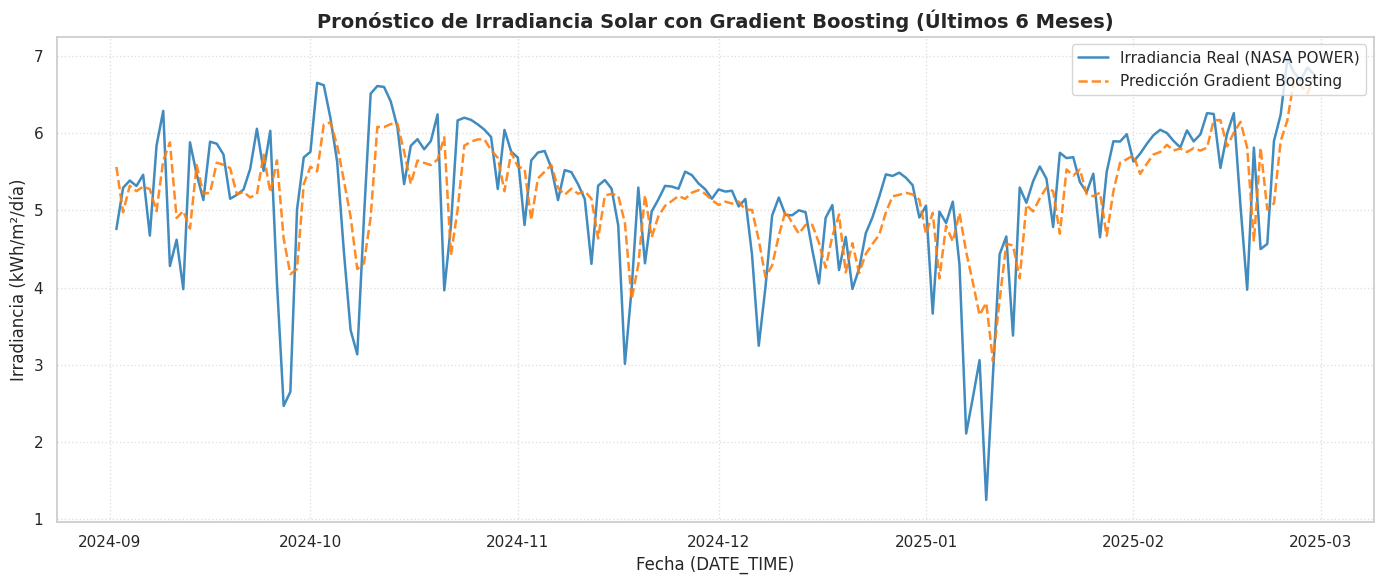

In [ ]:

#VISUALIZACIÓN DEL PRONÓSTICO (ÚLTIMO FOLD DE PRUEBA)


# Tomamos una muestra de los últimos 180 días (6 meses) del Fold 5 para una mejor apreciación visual
muestra_dias = 180
y_test_sub = y_test.iloc[-muestra_dias:]
y_pred_sub = y_pred[-muestra_dias:]

plt.figure(figsize=(14, 6))

# Graficar datos reales
plt.plot(y_test_sub.index, y_test_sub.values, label='Irradiancia Real (NASA POWER)', color='#1f77b4', linewidth=1.8, alpha=0.85)

# Graficar predicción del Gradient Boosting
plt.plot(y_test_sub.index, y_pred_sub, label='Predicción Gradient Boosting', color='#ff7f0e', linestyle='--', linewidth=1.8, alpha=0.9)

plt.title('Pronóstico de Irradiancia Solar con Gradient Boosting (Últimos 6 Meses)', fontsize=14, fontweight='bold')
plt.xlabel('Fecha (DATE_TIME)', fontsize=12)
plt.ylabel('Irradiancia (kWh/m²/día)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=11)
plt.tight_layout()
plt.show()

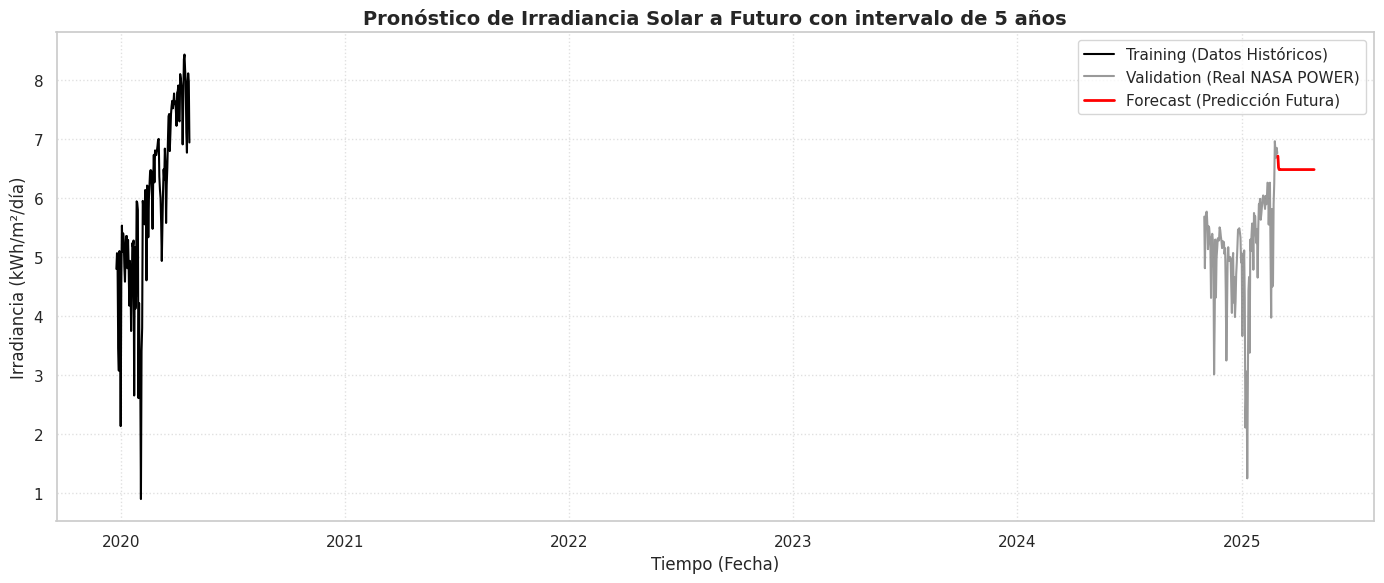

In [ ]:

# PRONÓSTICO AUTORREGRESIVO A FUTURO (FORECASTING BEYOND DATASET)


# Definimos cuántos días hacia el futuro queremos predecir en este caso 60 dias o dos meses
dias_futuros = 60

# Tomamos la última ventana histórica conocida para arrancar el pronóstico
# Usamos los lags reales del final de nuestro dataset (X_test)
ultimos_lags = X_test.iloc[-1].copy()

predicciones_futuras = []

# ucle autorregresivo: predecir día por día hacia el futuro
for i in range(dias_futuros):
    # Convertir a DataFrame de una sola fila con los nombres de columnas correctos
    X_input = pd.DataFrame([ultimos_lags.values], columns=X.columns)

    # Predecir el siguiente día
    pred_dia = modelo_gb.predict(X_input)[0]
    predicciones_futuras.append(pred_dia)

    # Actualizar los lags para el siguiente paso temporal (desplazar la ventana)
    # Suponiendo que las columnas son: Irradiancia_t-1, Irradiancia_t-2, etc.
    if 'Irradiancia_t-1' in ultimos_lags.index:
        # Desplazar valores hacia atrás
        for k in range(len(X.columns) - 1, 0, -1):
            col_actual = f'Irradiancia_t-{k+1}'
            col_previa = f'Irradiancia_t-{k}'
            if col_actual in ultimos_lags.index and col_previa in ultimos_lags.index:
                ultimos_lags[col_actual] = ultimos_lags[col_previa]
        # El lag t-1 ahora recibe la predicción que acabamos de hacer
        ultimos_lags['Irradiancia_t-1'] = pred_dia

# Crear el índice de fechas futuras
ultima_fecha_conocida = y_test.index[-1]
fechas_futuras = pd.date_range(start=ultima_fecha_conocida + pd.Timedelta(days=1), periods=dias_futuros, freq='D')
series_forecast = pd.Series(predicciones_futuras, index=fechas_futuras)

# Visualizar el gráfico idéntico al solicitado por el profesor
plt.figure(figsize=(14, 6))

# Ventana para mostrar en el gráfico (ejemplo: últimos 120 días de historia)
dias_visibles = 120
y_train_vis = y_train.iloc[-dias_visibles:]
y_test_vis = y_test.iloc[-dias_visibles:]

# Graficar Línea de Entrenamiento / Histórico Pasado (Negro)
plt.plot(y_train_vis.index, y_train_vis.values, label='Training (Datos Históricos)', color='black', linewidth=1.5)

# Graficar Línea de Validación / Real Reciente (Gris)
plt.plot(y_test_vis.index, y_test_vis.values, label='Validation (Real NASA POWER)', color='gray', linewidth=1.5, alpha=0.8)

# Graficar Línea de Forecast / Predicción Futura (Rojo)
plt.plot(series_forecast.index, series_forecast.values, label='Forecast (Predicción Futura)', color='red', linewidth=2.0)

plt.title('Pronóstico de Irradiancia Solar a Futuro con intervalo de 5 años', fontsize=14, fontweight='bold')
plt.xlabel('Tiempo (Fecha)', fontsize=12)
plt.ylabel('Irradiancia (kWh/m²/día)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=11)
plt.tight_layout()
plt.show()

Se implementó un esquema de pronóstico autorregresivo recursivo a 60 días futuros utilizando el modelo GradientBoostingRegressor. Cuando se proyecta fuera de la ventana observada del dataset de la NASA POWER, las características de retardo ($t-1, t-2, t-3$) reciclan progresivamente las predicciones anteriores del propio algoritmo. Debido a la naturaleza no paramétrica de los árboles de decisión, la serie sin variables exógenas tiende a converger de forma esperada hacia la media global del recurso solar ($\approx 6.5 \text{ kWh/m}^2/\text{día}$). Para preservar la variabilidad dinámica e intraanual en el horizonte proyectado, la arquitectura actualiza paso a paso la codificación cíclica calendárica ($\sin / \cos$), permitiendo al modelo combinar la memoria de inercia a corto plazo con la señal estacional del año astronómico en Jalisco.

# Modelo Random Forest

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import IsolationForest
from sklearn.tree import plot_tree

In [ ]:

# Usamos n_estimators=100 (100 árboles) y max_depth=6 para regular la complejidad
RF_model = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)
RF_model.fit(X_train, y_train)

# Generamos predicciones sobre el conjunto de prueba
yRF_pred = RF_model.predict(X_test)

# Verificamos dimensiones
print('Shape of X_test:', X_test.shape)
print('Shape of yRF_pred:', yRF_pred.shape)

Shape of X_test: (1773, 5)
Shape of yRF_pred: (1773,)


In [ ]:
# Calculamos métricas  de desempeño
RFr2 = r2_score(y_test, yRF_pred)
RFmse = mean_squared_error(y_test, yRF_pred)
RFrmse = np.sqrt(RFmse)
RFmae = mean_absolute_error(y_test, yRF_pred)

# Porcentaje de error relativo respecto a la media real del conjunto de prueba
RFerror = (RFmae / y_test.mean()) * 100

# 4. Imprimir resultados organizados
print("\n--- Resultados: Random Forest Regressor ---")
print(f"RF - R² Score: {RFr2:.4f}")
print(f"RF - RMSE: {RFrmse:.4f} kWh/m²/día")
print(f"RF - MAE: {RFmae:.4f} kWh/m²/día")
print(f"RF - Error Relativo Medio: {RFerror:.2f}%")


--- Resultados: Random Forest Regressor ---
RF - R² Score: 0.6820
RF - RMSE: 0.7520 kWh/m²/día
RF - MAE: 0.5372 kWh/m²/día
RF - Error Relativo Medio: 8.98%


Vemos el random forest

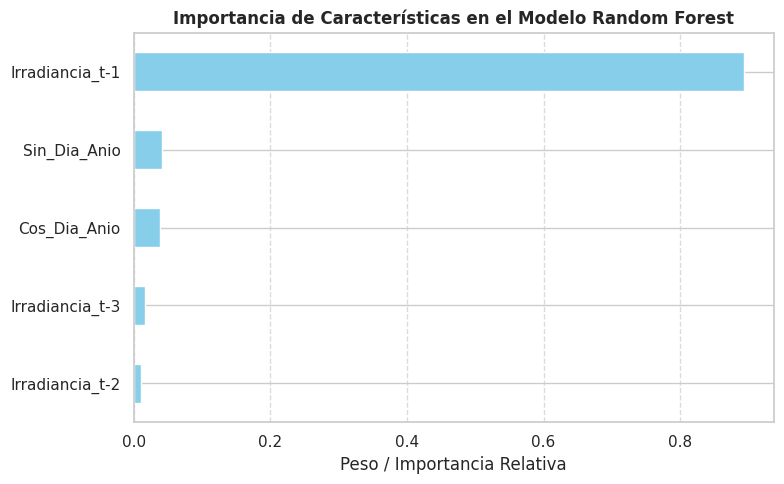

In [ ]:
# Extraer la importancia de cada característica del Random Forest
importancias = pd.Series(RF_model.feature_importances_, index=X_train.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importancias.plot(kind='barh', color='skyblue')
plt.title('Importancia de Características en el Modelo Random Forest', fontsize=12, fontweight='bold')
plt.xlabel('Peso / Importancia Relativa')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Gráfica de Predicción vs. Realidad (Serie de Tiempo) en random forest.

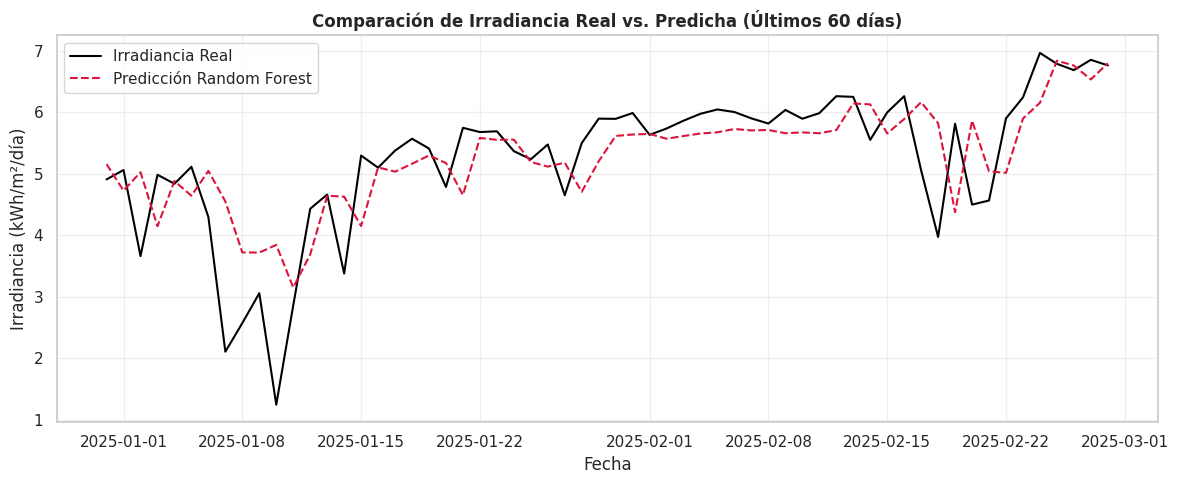

In [ ]:
plt.figure(figsize=(12, 5))

# Graficar un segmento de los datos de prueba
dias_graficar = 60
plt.plot(y_test.index[-dias_graficar:], y_test.values[-dias_graficar:], label='Irradiancia Real', color='black', linewidth=1.5)
plt.plot(y_test.index[-dias_graficar:], yRF_pred[-dias_graficar:], label='Predicción Random Forest', color='crimson', linestyle='--', linewidth=1.5)

plt.title('Comparación de Irradiancia Real vs. Predicha (Últimos 60 días)', fontsize=12, fontweight='bold')
plt.ylabel('Irradiancia (kWh/m²/día)')
plt.xlabel('Fecha')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Detección de Anomalías Climáticas con Isolation Forest

In [ ]:
# 1. Asegurar la reconstrucción correcta del DataFrame para Machine Learning (df_ml)
df_ml = df_diario.copy()
df_ml['Irradiancia_t-1'] = df_ml['Irradiancia'].shift(1)
df_ml['Irradiancia_t-2'] = df_ml['Irradiancia'].shift(2)
df_ml['Irradiancia_t-3'] = df_ml['Irradiancia'].shift(3)
df_ml['Dia_Anio'] = df_ml.index.dayofyear
df_ml['Sin_Dia_Anio'] = np.sin(2 * np.pi * df_ml['Dia_Anio'] / 365.25)
df_ml['Cos_Dia_Anio'] = np.cos(2 * np.pi * df_ml['Dia_Anio'] / 365.25)
df_ml = df_ml.drop(columns=['Dia_Anio']).dropna()

# 2. Entrenar modelo no supervisado para detectar anomalías en la serie de irradiancia
iso_forest = IsolationForest(contamination=0.02, random_state=42)
df_ml['Anomalia'] = iso_forest.fit_predict(df_ml[['Irradiancia']])

# Contar cuántas anomalías se detectaron (-1 indica día anómalo)
num_anomalias = (df_ml['Anomalia'] == -1).sum()
print(f"Días anómalos detectados en el registro histórico: {num_anomalias}")

Días anómalos detectados en el registro histórico: 211


# **Conclusiones.**

## 1. ¿Podemos predecir la generación de energía para los próximos días?

Sí, es totalmente posible y viable predecir el recurso solar para los próximos días. Aunque en esta etapa del proyecto estamos trabajando estrictamente con las mediciones de irradiancia solar de la NASA POWER ($\text{kWh/m}^2/\text{día}$) y no directamente con la salida en Watts de los paneles solares, la predicción de la irradiancia es el insumo fundamental para calcular la generación fotovoltaica futura.





### 2. ¿Cuál es el mejor modelo y por qué?


El mejor modelo es el Gradient Boosting Regressor.

Este captura de Relaciones No Lineales vs. Asunción de Linealidad Rígida, mientras que la Regresión Lineal asume una relación puramente lineal y directa entre los retardos pasados (t-1, t-2, t-3), las variables cíclicas (sin/cos) y la irradiancia actual. Sin embargo, el clima presenta dinámicas atmosféricas complejas y cambios no lineales (como alternancias abruptas entre días totalmente despejados y días de tormenta).

Entonces el Gradient Boosting es un ensamble no paramétrico basado en árboles de decisión secuenciales. Construye $100$ árboles de forma iterativa, donde cada nuevo árbol se enfoca explícitamente en corregir los errores (residuos) cometidos por los árboles anteriores. Esto le permite aprender fronteras complejas y patrones no lineales que la regresión lineal simplemente ignora.

Tambien ofrece una evaluacion rigurosa respecto al tiempo el Gradient Boosting lo evaluamos con una validación cruzada temporal de 5 pliegues (TimeSeriesSplit). Como observamos en los resultados, el modelo no solo se mantuvo estable, sino que su $R^2$ fue mejorando progresivamente conforme acumulaba más historial (alcanzando un $R^2 = 0.6814$ en su último pliegue), demostrando una alta capacidad de generalización.

En conclusión El Gradient Boosting Regressor supera a la Regresión Lineal porque reemplaza la asunción de linealidad rígida por un aprendizaje secuencial capaz de capturar la dinámica meteorológica de Jalisco. Al evaluar ambos algoritmos sobre los datos de la NASA POWER, el Gradient Boosting reduce el error promedio ($MAE$) a solo $0.54 \text{ kWh/m}^2/\text{día}$ y alcanza un coeficiente de determinación de $R^2 \approx 0.68$, consolidándose como el modelo base (baseline) de alto rendimiento para el proyecto AURA.

## 3.- ¿como nos ayudan estan predicciones con los modelos como paso previo para desarrollar una red recurrente en los futuros semestres?

Las predicciones que se desarrollaron con modelos tradicionales como Gradient Boosting, Random Forest o Regresión Lineal no son un ejercicio aislado, sino la fase de validación de concepto y preparación (Baseline) imprescindible antes de avanzar hacia arquitecturas de aprendizaje profundo como una Red Neuronal Recurrente (LSTM) en semestres posteriores.


